# Neumann-series inverse: uniform approximation and known-input amplification

The input is an explicitly specified positive Pauli matrix with four distinct eigenvalues and a complex, unbalanced prepared vector. The circuit implements a finite Neumann polynomial by actual coefficient PREPARE, signed Pauli SELECT and unprepare. No dense inverse or eigendecomposition makes a gate.

Exact rational coefficients support an analytic uniform approximation bound. Floating gate loading and synthesis have separate evidence and limits. The implementation and figures are original MIT code using Qiskit 2.6.2 (Apache-2.0), NumPy and SciPy (BSD-3-Clause).

In [1]:
from pathlib import Path
import sys, os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
root = Path.cwd()
if not (root/'src/openquantum/linear_inverse_lcu.py').exists() and (root.parent/'src/openquantum/linear_inverse_lcu.py').exists():
    root = root.parent
if (root/'src/openquantum/linear_inverse_lcu.py').exists():
    sys.path.insert(0, str(root/'src'))
elif (root/'code/src/openquantum/linear_inverse_lcu.py').exists():
    sys.path.insert(0, str(root/'code/src'))
from openquantum import linear_inverse_lcu as inv
from openquantum.linear_systems import accepted_observable_workload, decompose
terms = inv.structured_inverse_terms(2, '1/2')
degree = 12
prep = inv.default_preparation(2)
model = inv.neumann_coefficients(terms, degree)
A = SparsePauliOp.from_list([(p, float(c)) for c,p in model.input_terms]).to_matrix()
print('Matrix eigenvalues:', np.linalg.eigvalsh(A))
print('Exact polynomial terms:', len(model.coefficients))
print('Promised interval:', model.as_metadata()['promised_normalized_spectrum'])

Matrix eigenvalues: [0.5381966 0.7381966 0.7618034 0.9618034]
Exact polynomial terms: 6
Promised interval: [0.5, 1.0]


## A reciprocal across the promised interval

For $A=aI+\sum c_jP_j$, assume $a>r=\sum|c_j|$. Normalize $B=A/(a+r)$, so $\delta=(a-r)/(a+r)$ promises spectrum in $[\delta,1]$. The finite series is

$$T_K(B)=\delta\sum_{k=0}^K(I-B)^k.$$

Its scaled reciprocal error is at most $E=(1-\delta)^{K+1}$. Because the relative eigenvalue factor lies in $[1-E,1]$, normalized-state trace distance is at most $E/(2-E)$ and Pauli bias at most $2E/(2-E)$ in the exact polynomial model.

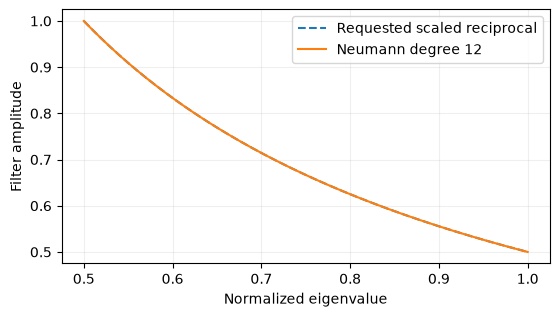

,degree,scaled operator error bound,conditional trace distance bound,conditional Pauli bias bound
0,12,0.000122,0.000061,0.000122


In [2]:
grid = np.linspace(float(model.delta), 1., 401)
polynomial = float(model.delta)*sum((1-grid)**k for k in range(degree+1))
fig, ax = plt.subplots(figsize=(6.3,3.3))
ax.plot(grid, float(model.delta)/grid, '--', label='Requested scaled reciprocal')
ax.plot(grid, polynomial, label=f'Neumann degree {degree}')
ax.set(xlabel='Normalized eigenvalue', ylabel='Filter amplitude')
ax.grid(alpha=.2); ax.legend(); plt.show()
display(pd.DataFrame([{
    'degree': degree,
    'scaled operator error bound': model.as_metadata()['scaled_inverse_operator_error_bound'],
    'conditional trace distance bound': model.as_metadata()['conditional_state_trace_distance_bound'],
    'conditional Pauli bias bound': model.as_metadata()['conditional_Pauli_bias_bound']
}]))

## Actual input and inverse access

The input is prepared with RY(0.63), RZ(0.41) on q0 and RY(0.37) on q1. The Pauli coefficients of $T_K$ are aggregated using exact rational arithmetic; PREPARE loads their absolute weights, SELECT applies their signed Pauli words, and inverse PREPARE removes the label loading. All-zero labels select $T_K/s$, where $s$ is the coefficient one-norm.

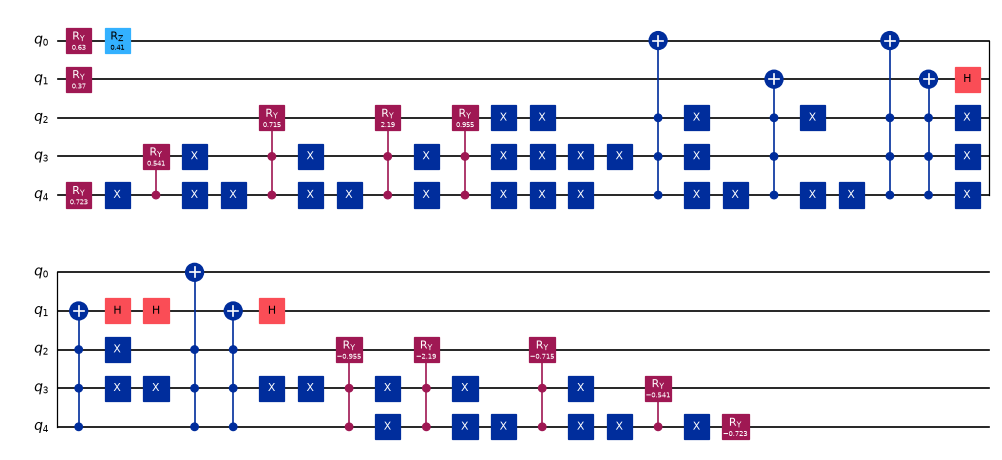

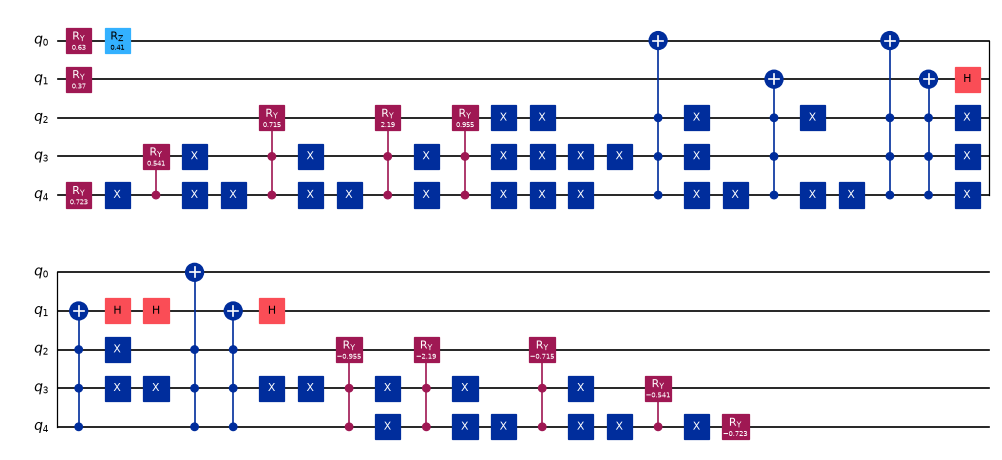

In [3]:
circuit = inv.prepared_inverse(terms, degree, prep, rounds=0)
display(circuit.draw(output='mpl', fold=24, scale=.6))

In [4]:
result = inv.compare_inverse(terms, degree, prep, rounds=0)
assert result['scaled_inverse_operator_error'] <= result['analytic_operator_error_bound'] + 1e-12
assert result['conditional_state_trace_distance_to_classical_solution'] <= result['analytic_conditional_trace_distance_bound'] + 1e-12
assert result['z_absolute_bias'] <= result['analytic_conditional_Pauli_bias_bound'] + 2e-12
display(pd.DataFrame([{
    'actual condition': result['actual_condition_number'],
    'success': result['success_probability'],
    'solution trace distance': result['conditional_state_trace_distance_to_classical_solution'],
    'Z from circuit': result['z_quantum'],
    'Z from classical solve': result['z_classical_solution'],
    'Z bias': result['z_absolute_bias']
}]))

,actual condition,success,solution trace distance,Z from circuit,Z from classical solve,Z bias
0,1.787086,0.800942,0.000015,0.640378,0.640357,0.000021


## Amplification of the known prepared input

Let $W$ include the actual preparation and LCU, $S_g=I-2\Pi_{\rm labels=0}$, and $S_0=I-2|0\cdots0\rangle\langle0\cdots0|$ on every initial wire. One Grover round after $W$ is chronological $S_g,W^\dagger,S_0,W$, plus a global minus sign.

The full initial-state reflection makes this ordinary known-input amplitude amplification. It does not attempt oblivious amplification of an unknown nonunitary inverse. Its successful state direction is unchanged in the ideal model. Integer-round success is nonmonotone, so more rounds need not improve it.

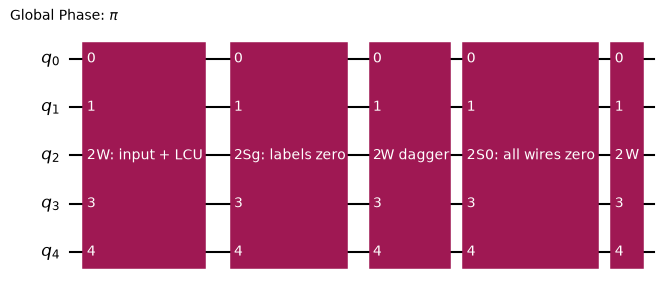

,rounds,full W/Wdagger calls,success,primitive operations,depth
0,0,1,0.800942,325,269
1,1,3,0.033257,1065,886
2,2,5,0.456205,1805,1503
3,3,7,0.990872,2545,2120
4,4,9,0.273354,3285,2737


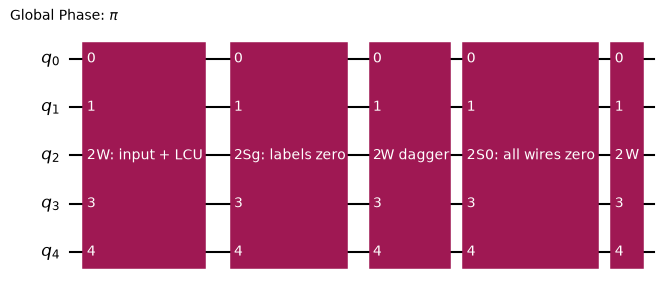

In [5]:
source = inv.prepared_inverse(terms, degree, prep, rounds=0)
good = inv.zero_reflection(source.num_qubits, range(model.n_system, source.num_qubits))
initial = inv.zero_reflection(source.num_qubits, range(source.num_qubits))
diagram = QuantumCircuit(source.num_qubits)
diagram.append(source.to_gate(label='W: input + LCU'), range(source.num_qubits))
diagram.append(good.to_gate(label='Sg: labels zero'), range(source.num_qubits))
diagram.append(source.inverse().to_gate(label='W dagger'), range(source.num_qubits))
diagram.append(initial.to_gate(label='S0: all wires zero'), range(source.num_qubits))
diagram.append(source.to_gate(label='W'), range(source.num_qubits))
diagram.global_phase = math.pi
display(diagram.draw(output='mpl', fold=26, scale=.75))
# These boxes have the actual gate definitions above; exports contain primitive gates.
rows=[]
for rounds in range(5):
    amplified=inv.compare_inverse(terms, degree, prep, rounds=rounds)
    measured=decompose(inv.measured_inverse_trial(terms,degree,prep,rounds=rounds))
    assert abs(amplified['success_probability']-amplified['amplification_prediction']) < 1e-12
    assert amplified['conditional_state_trace_distance_to_unamplified_polynomial'] < 1e-12
    rows.append({'rounds':rounds,'full W/Wdagger calls':2*rounds+1,
                 'success':amplified['success_probability'],
                 'primitive operations':len(measured.data)-measured.count_ops().get('barrier',0),
                 'depth':measured.depth()})
display(pd.DataFrame(rows))

## Degree, condition and complete readout

The classical series aggregation can grow exponentially in the number of Pauli words and is capped. Once aggregated, the quantum access circuit has one explicit SELECT term per nonzero polynomial coefficient; its gate count is not simply $K$ oracle calls. Normalization and success still determine fresh-trial repetitions. The selected output is one conditional Z(q0) mean, not every solution entry.

,K,actual Z bias,uniform Z bias bound,solution trace distance
0,0,1.676702e-01,6.666667e-01,1.378205e-01
1,1,8.577899e-02,2.857143e-01,6.377460e-02
2,2,4.224693e-02,1.333333e-01,3.043950e-02
3,4,9.633506e-03,3.174603e-02,6.819294e-03
4,8,4.533698e-04,1.955034e-03,3.197365e-04
5,12,2.070465e-05,1.220778e-04,1.460108e-05
6,16,9.420924e-07,7.629424e-06,6.643777e-07
7,24,1.948828e-09,2.980232e-08,1.374346e-09
8,32,4.031331e-12,1.164153e-10,2.842734e-12


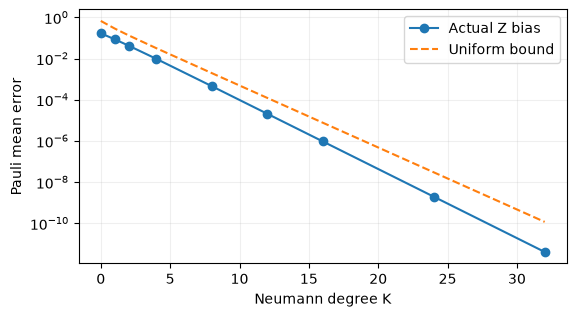

In [6]:
convergence=[]
for k in (0,1,2,4,8,12,16,24,32):
    check=inv.compare_inverse(terms,k,prep,rounds=0)
    convergence.append({'K':k,'actual Z bias':check['z_absolute_bias'],
                        'uniform Z bias bound':check['analytic_conditional_Pauli_bias_bound'],
                        'solution trace distance':check['conditional_state_trace_distance_to_classical_solution']})
table=pd.DataFrame(convergence)
display(table)
fig,ax=plt.subplots(figsize=(6.3,3.3))
ax.semilogy(table['K'],table['actual Z bias'],'o-',label='Actual Z bias')
ax.semilogy(table['K'],table['uniform Z bias bound'],'--',label='Uniform bound')
ax.set(xlabel='Neumann degree K',ylabel='Pauli mean error')
ax.grid(alpha=.2);ax.legend();plt.show()

In [7]:
ledger=[]
for rounds in (0,1,2):
    check=inv.compare_inverse(terms,degree,prep,rounds=rounds)
    compiled=decompose(inv.measured_inverse_trial(terms,degree,prep,rounds=rounds))
    workload=accepted_observable_workload(check['success_probability'])
    ledger.append({'rounds':rounds,'logical qubits':compiled.num_qubits,
                   'CX':compiled.count_ops().get('cx',0),
                   'continuous rotations':sum(compiled.count_ops().get(g,0) for g in ('rx','ry','rz')),
                   'measurements':compiled.count_ops()['measure'],
                   'accepted samples proposal':workload['accepted_samples'],
                   'attempts per slot proposal':workload['attempt_cap_per_accepted_slot'],
                   'total capped attempts proposal':workload['total_capped_attempts']})
display(pd.DataFrame(ledger))

,rounds,logical qubits,CX,continuous rotations,measurements,accepted samples proposal,attempts per slot proposal,total capped attempts proposal
0,0,5,150,156,5,13315,10,133150
1,1,5,492,501,5,13315,438,5831970
2,2,5,834,846,5,13315,25,332875


The workload above is an **unexecuted ideal proposal** for .03 statistical error, .005 statistical failure and a separate .005 no-acceptance allowance. Every rejected attempt pays all source, reflection and measurement gates. Clean initialization timing/faults and concrete Clifford+T synthesis are excluded. The analytic polynomial bound and numerical checks do not certify floating gate loading or hardware accuracy. The separate QDK mean-fit projection is conditional.

## Optional live exploration

Live Python controls regenerate a bounded two-qubit circuit at changed gap and degree. Static publication preserves the checked outputs; it needs no maintained kernel server.

In [8]:
if not os.environ.get('OPENQUANTUM_STATIC_BUILD'):
    import ipywidgets as widgets
    def explore(delta=.5,K=12):
        chosen=inv.structured_inverse_terms(2,delta)
        check=inv.compare_inverse(chosen,K,inv.default_preparation(2))
        display(pd.DataFrame([{'promised gap':delta,'degree':K,'actual condition':check['actual_condition_number'],
                               'Z bias':check['z_absolute_bias'],'uniform Z bound':check['analytic_conditional_Pauli_bias_bound'],
                               'success':check['success_probability']}]))
    display(widgets.interactive(explore,delta=widgets.SelectionSlider(options=[.25,.5,.75],value=.5),
                                K=widgets.IntSlider(min=0,max=24,value=12)))